# Сверточные нейронные сети


В данной работе мы рассмотрим бинарный классификатор. Изображения были загружены из набора
<a href="https://www.kaggle.com/datasets/ifeanyinneji/donkeys-horses-zebra-images-dataset">Donkeys, Horses & Zebra Images Dataset</a>.
В наборе используются два класса: `horse` и `zebra`.


Библиотечки:


In [1]:
from __future__ import annotations

import time
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms


<p>Загрузка данных и предварительная обработка изображений.
<p>Данные берутся из prepared-датасета, созданного в notebook `8.1`.
<p>Далее анализируем папки `train`, `val` и `test`, получаем путь для каждого изображения и сохраняем его в списке.


In [2]:
PRACTICE_DIR = Path.cwd()
DATASET_DIR = PRACTICE_DIR / ".data" / "donkeys-horses-zebra-prepared"
TRAIN_DIR = DATASET_DIR / "train"
VAL_DIR = DATASET_DIR / "val"
TEST_DIR = DATASET_DIR / "test"
ALLOWED_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

if not TRAIN_DIR.is_dir() or not VAL_DIR.is_dir() or not TEST_DIR.is_dir():
    raise FileNotFoundError("Не найден prepared-датасет. Сначала выполните notebook 8.1.")

class_names = sorted([
    folder.name for folder in TRAIN_DIR.iterdir() if folder.is_dir()
])

# Метка каждого класса задается по имени папки.
class_to_idx = {class_name: idx for idx, class_name in enumerate(class_names)}
idx_to_class = {idx: class_name for class_name, idx in class_to_idx.items()}
NUM_CLASSES = len(class_names)

train = []
y_train = []
val = []
y_val = []
test = []
y_test = []

for class_name in class_names:
    train_folder = TRAIN_DIR / class_name
    val_folder = VAL_DIR / class_name
    test_folder = TEST_DIR / class_name

    for file_path in sorted(train_folder.iterdir()):
        if file_path.is_file() and file_path.suffix.lower() in ALLOWED_EXTENSIONS:
            train.append(str(file_path))
            y_train.append(class_to_idx[class_name])

    for file_path in sorted(val_folder.iterdir()):
        if file_path.is_file() and file_path.suffix.lower() in ALLOWED_EXTENSIONS:
            val.append(str(file_path))
            y_val.append(class_to_idx[class_name])

    for file_path in sorted(test_folder.iterdir()):
        if file_path.is_file() and file_path.suffix.lower() in ALLOWED_EXTENSIONS:
            test.append(str(file_path))
            y_test.append(class_to_idx[class_name])

print("Классы:", class_names)
print("Количество классов:", NUM_CLASSES)
print("train size", len(train))
print("val size", len(val))
print("test size", len(test))

print("\nКоличество изображений по классам в train:")
for class_name in class_names:
    class_idx = class_to_idx[class_name]
    print(class_name, "-", y_train.count(class_idx))

print("\nКоличество изображений по классам в val:")
for class_name in class_names:
    class_idx = class_to_idx[class_name]
    print(class_name, "-", y_val.count(class_idx))

print("\nКоличество изображений по классам в test:")
for class_name in class_names:
    class_idx = class_to_idx[class_name]
    print(class_name, "-", y_test.count(class_idx))


Классы: ['horse', 'zebra']
Количество классов: 2
train size 496
val size 122
test size 156

Количество изображений по классам в train:
horse - 308
zebra - 188

Количество изображений по классам в val:
horse - 76
zebra - 46

Количество изображений по классам в test:
horse - 96
zebra - 60


Далее каждый путь используется для загрузки изображения. Изображение конвертируется в `RGB`, а метка берётся из папки класса.
Для изображения требуется дополнительное преобразование, поэтому будет создан объект преобразования для изменения размера изображения до `224x224` и нормализации его значений.
Для обучающей выборки используется аугментация. Для валидационной и тестовой выборок аугментация не применяется.


In [3]:
# image normalization
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# image normalization
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# preprocessing of images
class ImageDataset(Dataset):
    def __init__(self, image_paths, labels, transform):
        super().__init__()
        self.paths = image_paths
        self.labels = labels
        self.len = len(self.paths)
        self.transform = transform

    def __len__(self):
        return self.len

    def __getitem__(self, index):
        path = self.paths[index]
        image = Image.open(path).convert('RGB')
        image = self.transform(image)
        label = self.labels[index]
        return image, label


Воспользуемся классом `ImageDataset` для преобразования обучающей, валидационной и тестовой выборок и переведём их в формат, который PyTorch может использовать для обучения модели.


In [4]:
BATCH_SIZE = 16

# create train dataset
train_ds = ImageDataset(train, y_train, train_transform)
train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
print(len(train_ds), len(train_dl))

# create validation dataset
val_ds = ImageDataset(val, y_val, test_transform)
val_dl = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
print(len(val_ds), len(val_dl))

# create test dataset
test_ds = ImageDataset(test, y_test, test_transform)
test_dl = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)
print(len(test_ds), len(test_dl))


496 31
122 8
156 10


<p>Сверточная архитектура
<p>Рассмотрим архитектуру: 3 сверточных слоя и 3 полносявзных слоя. Эта архитектура не оптимальна, но служит для тестирования модели. Попробуйте поэксперементировать и изменить эту архитектуру, чтобы получить другие результаты.


In [5]:
class ImageConvNet(nn.Module):

    def __init__(self, num_classes):
        super().__init__()

        # convolutional layers
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=(5, 5), stride=2, padding=1)
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=(5, 5), stride=2, padding=1)
        self.conv3 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=(3, 3), padding=1)

        # connected layers
        self.fc1 = nn.Linear(in_features=64 * 6 * 6, out_features=500)
        self.fc2 = nn.Linear(in_features=500, out_features=50)
        # Размер выходного слоя равен количеству классов.
        self.fc3 = nn.Linear(in_features=50, out_features=num_classes)

    def forward(self, X):

        X = F.relu(self.conv1(X))
        X = F.max_pool2d(X, 2)

        X = F.relu(self.conv2(X))
        X = F.max_pool2d(X, 2)

        X = F.relu(self.conv3(X))
        X = F.max_pool2d(X, 2)

        X = X.view(X.shape[0], -1)
        X = F.relu(self.fc1(X))
        X = F.relu(self.fc2(X))
        X = self.fc3(X)

        return X


<p>Обучение модели
<p>Обратите внимание, что функции точности и потерь загружаются из библиотек PyTorch, а показатели производительности рассчитываются вручную.


In [6]:
# Create instance of the model
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
print("device:", device)

model = ImageConvNet(num_classes=NUM_CLASSES).to(device)

losses = []
accuracies = []
epoches = 10
start = time.time()
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# Model Training...
for epoch in range(epoches):

    model.train()
    epoch_loss = 0
    epoch_accuracy = 0

    for X, y in train_dl:

        X = X.to(device)
        y = y.to(device)

        preds = model(X)
        loss = loss_fn(preds, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        accuracy = (preds.argmax(dim=1) == y).float().mean()
        epoch_accuracy += accuracy.item()
        epoch_loss += loss.item()
        print('.', end='', flush=True)

    epoch_accuracy = epoch_accuracy / len(train_dl)
    accuracies.append(epoch_accuracy)
    epoch_loss = epoch_loss / len(train_dl)
    losses.append(epoch_loss)

    print("\n --- Epoch: {}, train loss: {:.4f}, train acc: {:.4f}, time: {:.2f}".format(
        epoch, epoch_loss, epoch_accuracy, time.time() - start
    ))

    # validation set accuracy
    model.eval()
    with torch.no_grad():

        val_epoch_loss = 0
        val_epoch_accuracy = 0

        for val_X, val_y in val_dl:

            val_X = val_X.to(device)
            val_y = val_y.to(device)

            val_preds = model(val_X)
            val_loss = loss_fn(val_preds, val_y)

            val_epoch_loss += val_loss.item()
            val_accuracy = (val_preds.argmax(dim=1) == val_y).float().mean()
            val_epoch_accuracy += val_accuracy.item()

        val_epoch_accuracy = val_epoch_accuracy / len(val_dl)
        val_epoch_loss = val_epoch_loss / len(val_dl)

        print("Epoch: {}, val loss: {:.4f}, val acc: {:.4f}, time: {:.2f}\n".format(
            epoch, val_epoch_loss, val_epoch_accuracy, time.time() - start
        ))


device: mps
...............................
 --- Epoch: 0, train loss: 0.4947, train acc: 0.7802, time: 0.90
Epoch: 0, val loss: 0.2616, val acc: 0.8875, time: 1.02

...............................
 --- Epoch: 1, train loss: 0.2674, train acc: 0.8851, time: 1.55
Epoch: 1, val loss: 0.2171, val acc: 0.9484, time: 1.64

...............................
 --- Epoch: 2, train loss: 0.2935, train acc: 0.8871, time: 2.22
Epoch: 2, val loss: 0.2300, val acc: 0.9078, time: 2.32

...............................
 --- Epoch: 3, train loss: 0.2326, train acc: 0.9234, time: 2.90
Epoch: 3, val loss: 0.1904, val acc: 0.9406, time: 3.01

...............................
 --- Epoch: 4, train loss: 0.1958, train acc: 0.9335, time: 3.62
Epoch: 4, val loss: 0.2713, val acc: 0.9094, time: 3.72

...............................
 --- Epoch: 5, train loss: 0.2324, train acc: 0.9153, time: 4.35
Epoch: 5, val loss: 0.1547, val acc: 0.9484, time: 4.46

...............................
 --- Epoch: 6, train loss: 0.241

<p>Финальная оценка на тестовой выборке
<p>После завершения обучения отдельно проверим модель на тестовой выборке.


In [7]:
model.eval()
with torch.no_grad():

    test_epoch_loss = 0
    test_epoch_accuracy = 0

    for test_X, test_y in test_dl:

        test_X = test_X.to(device)
        test_y = test_y.to(device)

        test_preds = model(test_X)
        test_loss = loss_fn(test_preds, test_y)

        test_epoch_loss += test_loss.item()
        test_accuracy = (test_preds.argmax(dim=1) == test_y).float().mean()
        test_epoch_accuracy += test_accuracy.item()

    test_epoch_accuracy = test_epoch_accuracy / len(test_dl)
    test_epoch_loss = test_epoch_loss / len(test_dl)

    print("Test loss: {:.4f}, test acc: {:.4f}".format(
        test_epoch_loss, test_epoch_accuracy
    ))


Test loss: 0.3810, test acc: 0.8438


<p>Прогнозы
<p>Сделаем прогнозы для нескольких изображений из тестовой выборки. Для каждого изображения будет показан настоящий класс, предсказанный класс и вероятность предсказанного класса.


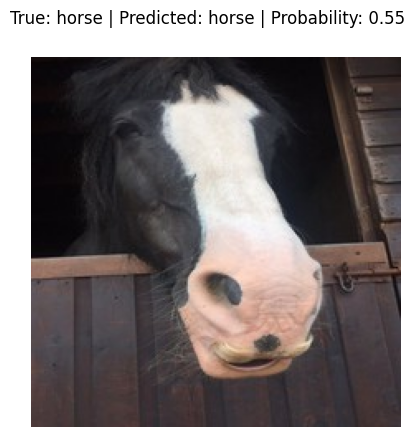

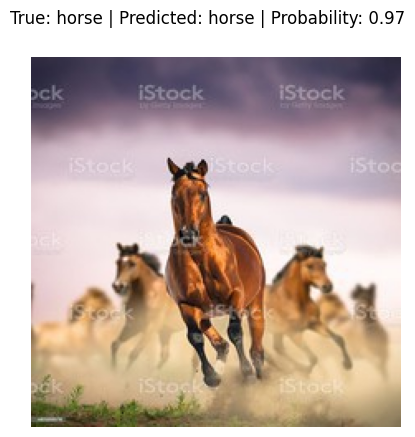

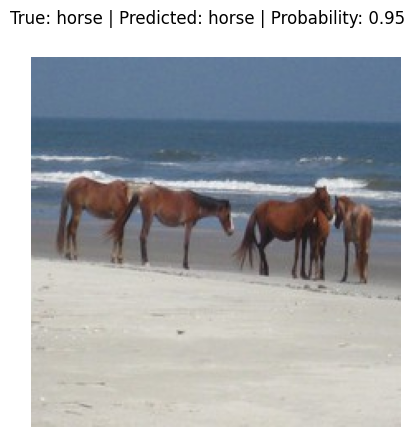

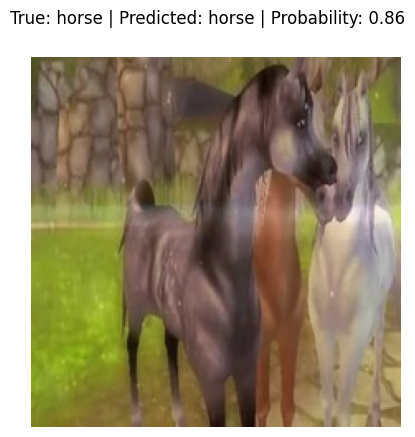

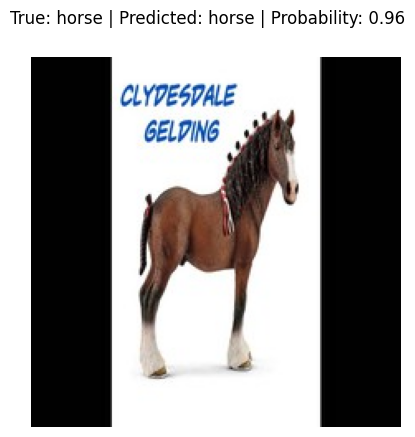

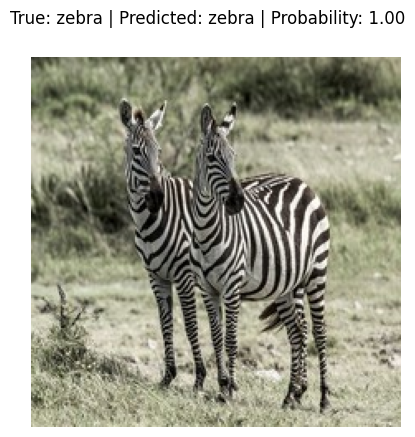

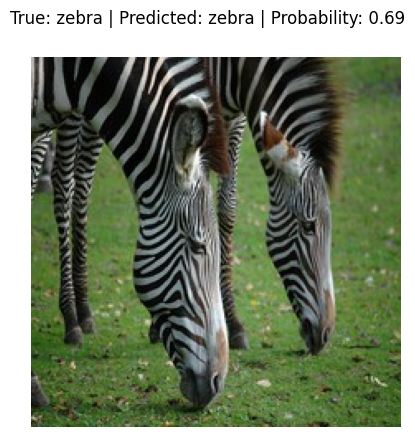

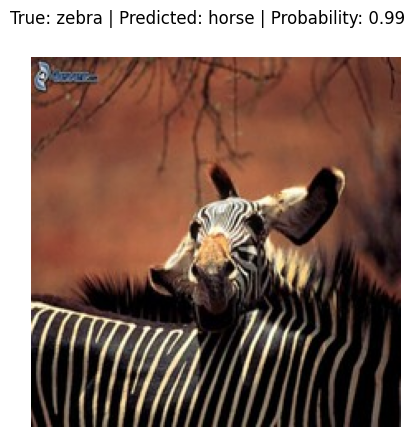

In [8]:
# display some predictions
model.eval()

for img_path, true_label in zip(test[::20], y_test[::20]):

    pil_im = Image.open(img_path).convert('RGB')
    X = test_transform(pil_im).unsqueeze(0).to(device)

    with torch.no_grad():
        preds = model(X)
        probs = F.softmax(preds, dim=1)[0].cpu()

    pred_idx = int(probs.argmax())
    pred_class = idx_to_class[pred_idx]
    true_class = idx_to_class[true_label]
    pred_prob = float(probs[pred_idx])

    title = f"True: {true_class} | Predicted: {pred_class} | Probability: {pred_prob:.2f}"

    plt.figure()
    plt.imshow(pil_im)
    plt.suptitle(title)
    plt.axis('off')
    plt.show()


<p>Матрица ошибок
<p>Построим матрицу ошибок по тестовой выборке.


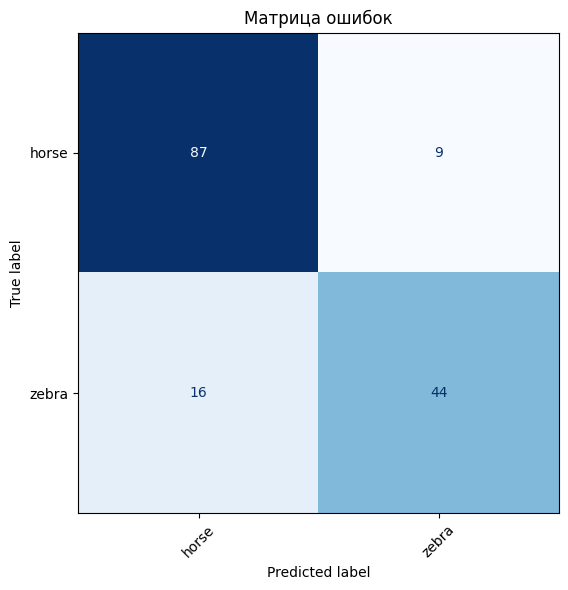

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

model.eval()
true_labels = []
predicted_labels = []

with torch.no_grad():
    for test_X, test_y in test_dl:
        test_X = test_X.to(device)
        preds = model(test_X)
        pred_classes = preds.argmax(dim=1).cpu().numpy()

        true_labels.extend(test_y.numpy())
        predicted_labels.extend(pred_classes)

cm = confusion_matrix(true_labels, predicted_labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap='Blues', xticks_rotation=45, colorbar=False)
ax.set_title("Матрица ошибок")
plt.tight_layout()
plt.show()
